In [1]:
import sys

print(sys.executable)

c:\Users\sable\DF-Analytics-2026-Assessment-SableDayaram\venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

train_df = pd.read_csv("../data/raw/Census_income_train.csv")
test_df = pd.read_csv("../data/raw/Census_income_test.csv")

print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

Matplotlib is building the font cache; this may take a moment.


Training data shape: (32560, 15)
Testing data shape: (16281, 15)


In [3]:
train_df.head()

,Age,Workclass,fnlwgt,Education,Education-num,Marital status,Occupation,Relationship,Race,Sex,Capital-gain,Capital-loss,Hours-per-week,Native-country,Income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32560 entries, 0 to 32559
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Age             32560 non-null  int64
 1   Workclass       32560 non-null  str  
 2   fnlwgt          32560 non-null  int64
 3   Education       32560 non-null  str  
 4   Education-num   32560 non-null  int64
 5   Marital status  32560 non-null  str  
 6   Occupation      32560 non-null  str  
 7   Relationship    32560 non-null  str  
 8   Race            32560 non-null  str  
 9   Sex             32560 non-null  str  
 10  Capital-gain    32560 non-null  int64
 11  Capital-loss    32560 non-null  int64
 12  Hours-per-week  32560 non-null  int64
 13  Native-country  32560 non-null  str  
 14  Income          32560 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [5]:
train_df.describe(include="all")

,Age,Workclass,fnlwgt,Education,Education-num,Marital status,Occupation,Relationship,Race,Sex,Capital-gain,Capital-loss,Hours-per-week,Native-country,Income
count,32560.000000,32560,3.256000e+04,32560,32560.000000,32560,32560,32560,32560,32560,32560.000000,32560.000000,32560.000000,32560,32560
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,41,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22695,NaN,10501,NaN,14976,4140,13193,27815,21790,NaN,NaN,NaN,29170,24719
mean,38.581849,NaN,1.897833e+05,NaN,10.080682,NaN,NaN,NaN,NaN,NaN,1077.681941,87.238790,40.437469,NaN,NaN
std,13.640593,NaN,1.055478e+05,NaN,2.572760,NaN,NaN,NaN,NaN,NaN,7385.403083,402.795459,12.347618,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178315e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783630e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370545e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [6]:
print("Missing values:")
print(train_df.isnull().sum())

print("\nDuplicate rows:", train_df.duplicated().sum())

Missing values:
Age               0
Workclass         0
fnlwgt            0
Education         0
Education-num     0
Marital status    0
Occupation        0
Relationship      0
Race              0
Sex               0
Capital-gain      0
Capital-loss      0
Hours-per-week    0
Native-country    0
Income            0
dtype: int64

Duplicate rows: 24


In [7]:
print(train_df["Income"].value_counts())

print("\nTarget distribution (%):")
print(train_df["Income"].value_counts(normalize=True) * 100)

Income
<=50K    24719
>50K      7841
Name: count, dtype: int64

Target distribution (%):
Income
<=50K    75.918305
>50K     24.081695
Name: proportion, dtype: float64


In [ ]:
categorical_columns = train_df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(train_df[col].value_counts().head(10))


Workclass:
Workclass
Private             22695
Self-emp-not-inc     2541
Local-gov            2093
?                    1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

Education:
Education
HS-grad         10501
Some-college     7290
Bachelors        5355
Masters          1723
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
Name: count, dtype: int64

Marital status:
Marital status
Married-civ-spouse       14976
Never-married            10682
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64

Occupation:
Occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770
Sales                3650
Other-service        

C:\Users\sable\AppData\Local\Temp\ipykernel_13656\1108314510.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = train_df.select_dtypes(include="object").columns


In [9]:
(train_df == "?").sum()

Age               0
Workclass         0
fnlwgt            0
Education         0
Education-num     0
Marital status    0
Occupation        0
Relationship      0
Race              0
Sex               0
Capital-gain      0
Capital-loss      0
Hours-per-week    0
Native-country    0
Income            0
dtype: int64

In [10]:
train_df[train_df.duplicated()].head(10)

,Age,Workclass,fnlwgt,Education,Education-num,Marital status,Occupation,Relationship,Race,Sex,Capital-gain,Capital-loss,Hours-per-week,Native-country,Income
4881,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
5104,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
9171,21,Private,250051,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,10,United-States,<=50K
11631,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K
13084,25,Private,195994,1st-4th,2,Never-married,Priv-house-serv,Not-in-family,White,Female,0,0,40,Guatemala,<=50K
15059,21,Private,243368,Preschool,1,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,50,Mexico,<=50K
17040,46,Private,173243,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
18555,30,Private,144593,HS-grad,9,Never-married,Other-service,Not-in-family,Black,Male,0,0,40,?,<=50K
18698,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
21317,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K


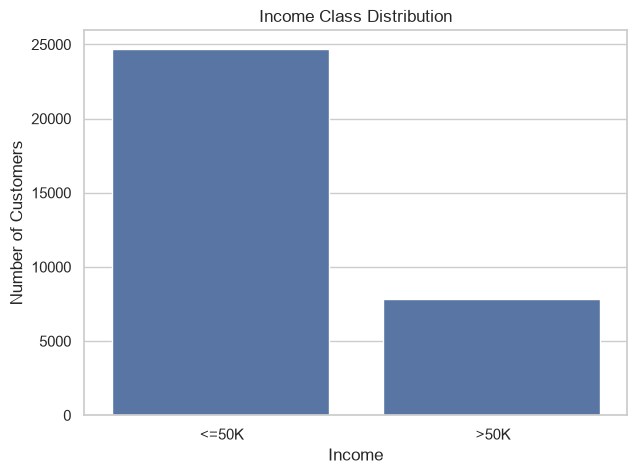

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=train_df, x="Income")

plt.title("Income Class Distribution")
plt.xlabel("Income")
plt.ylabel("Number of Customers")

plt.show()

In [12]:
# Count '?' values in every column
(train_df == "?").sum()

Age               0
Workclass         0
fnlwgt            0
Education         0
Education-num     0
Marital status    0
Occupation        0
Relationship      0
Race              0
Sex               0
Capital-gain      0
Capital-loss      0
Hours-per-week    0
Native-country    0
Income            0
dtype: int64

In [13]:
(test_df == "?").sum()

Age               0
Workclass         0
fnlwgt            0
Education         0
Education-num     0
Marital status    0
Occupation        0
Relationship      0
Race              0
Sex               0
Capital-gain      0
Capital-loss      0
Hours-per-week    0
Native-country    0
Income            0
dtype: int64

In [14]:
# Replace '?' with NaN in both datasets
train_df.replace("?", np.nan, inplace=True)
test_df.replace("?", np.nan, inplace=True)

# Check missing values again
print("Training missing values:")
print(train_df.isnull().sum())

print("\nTesting missing values:")
print(test_df.isnull().sum())

Training missing values:
Age               0
Workclass         0
fnlwgt            0
Education         0
Education-num     0
Marital status    0
Occupation        0
Relationship      0
Race              0
Sex               0
Capital-gain      0
Capital-loss      0
Hours-per-week    0
Native-country    0
Income            0
dtype: int64

Testing missing values:
Age               0
Workclass         0
fnlwgt            0
Education         0
Education-num     0
Marital status    0
Occupation        0
Relationship      0
Race              0
Sex               0
Capital-gain      0
Capital-loss      0
Hours-per-week    0
Native-country    0
Income            0
dtype: int64


### Initial Data Quality Findings

1. Training dataset contains 32,560 records and 15 columns.
2. Testing dataset contains 16,281 records and 15 columns.
3. The target variable is Income.
4. The target distribution is imbalanced:
   - <=50K: 75.92%
   - >50K: 24.08%
5. The training dataset contains 24 duplicate records.
6. Missing categorical values are represented using '?'.
7. The problem is formulated as a binary classification task.

In [15]:
print("Remaining '?' in training:", (train_df == "?").sum().sum())
print("Remaining '?' in testing:", (test_df == "?").sum().sum())

print("\nTraining missing values:", train_df.isnull().sum().sum())
print("Testing missing values:", test_df.isnull().sum().sum())

Remaining '?' in training: 0
Remaining '?' in testing: 0

Training missing values: 0
Testing missing values: 0


In [16]:
print("Training duplicates:", train_df.duplicated().sum())
print("Testing duplicates:", test_df.duplicated().sum())

Training duplicates: 24
Testing duplicates: 5


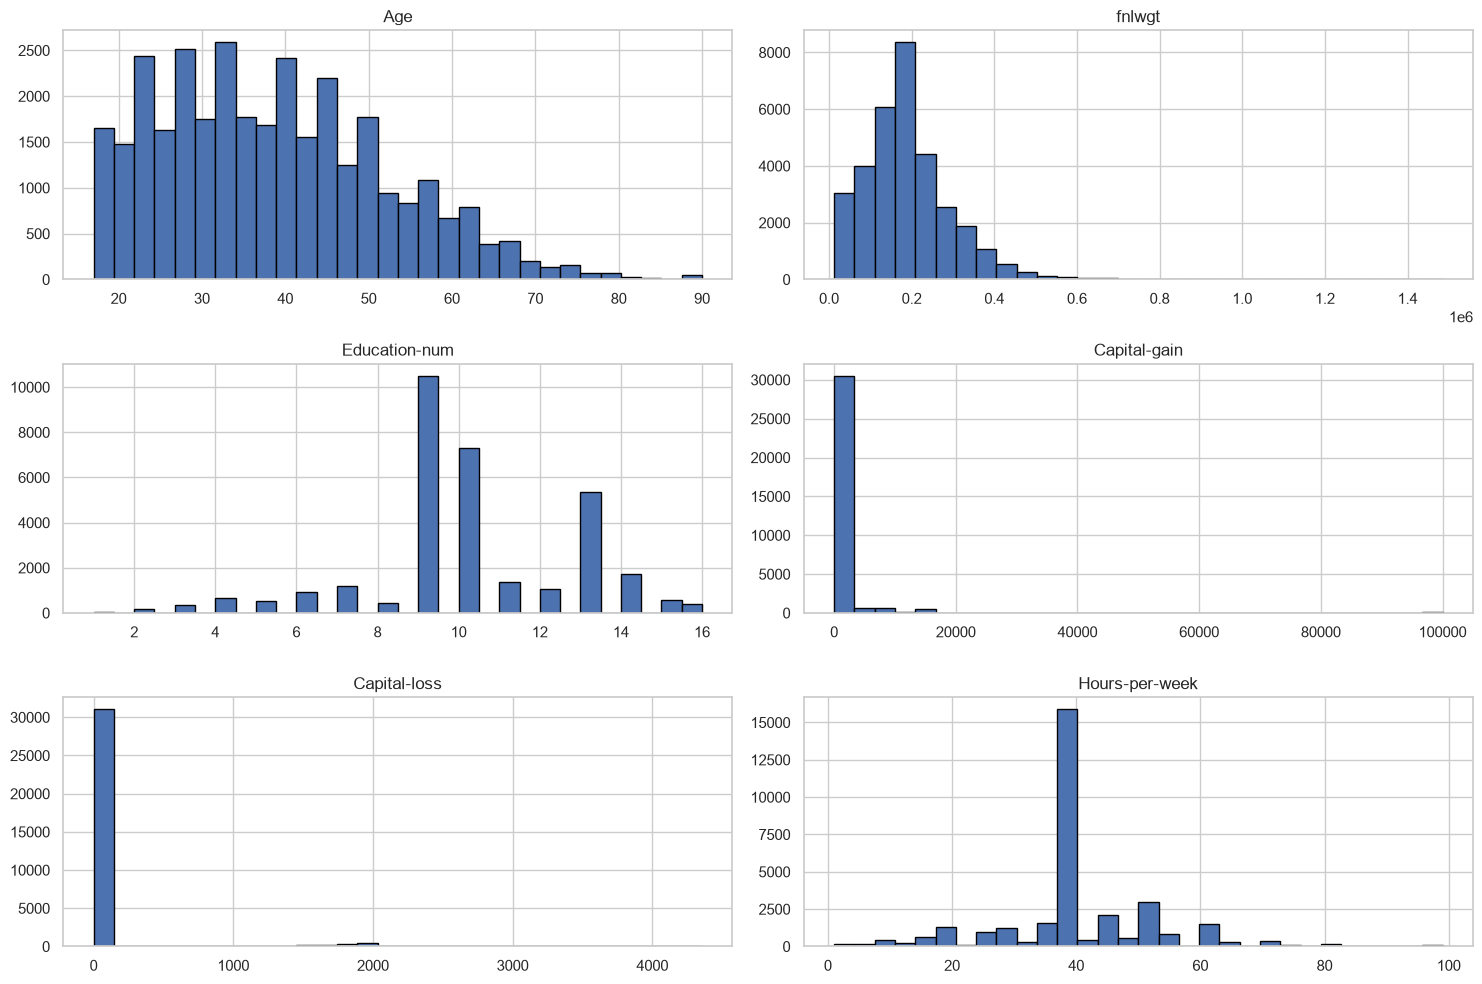

In [17]:
numerical_columns = train_df.select_dtypes(include=np.number).columns

train_df[numerical_columns].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

In [18]:
# Remove duplicate records
train_df = train_df.drop_duplicates().reset_index(drop=True)
test_df = test_df.drop_duplicates().reset_index(drop=True)

print("Training shape after removing duplicates:", train_df.shape)
print("Testing shape after removing duplicates:", test_df.shape)

Training shape after removing duplicates: (32536, 15)
Testing shape after removing duplicates: (16276, 15)


### Numerical Feature Analysis

1. Age: Most individuals are between 20 and 50 years old.
2. fnlwgt: Highly right-skewed distribution.
3. Education-num: Distinct peaks at education levels 9, 10 and 13.
4. Capital-gain: Highly right-skewed with many zero values.
5. Capital-loss: Highly right-skewed with many zero values.
6. Hours-per-week: Strong concentration around 40 working hours.

### Observations

- Several numerical features exhibit skewness.
- Capital-gain and Capital-loss contain many zero values.
- Some features have extreme values that require further investigation.
- We should avoid blindly removing outliers because extreme values may represent genuine observations.

In [19]:
categorical_columns = train_df.select_dtypes(
    include=["object", "str"]
).columns.drop("Income")

for col in categorical_columns:
    print(f"\n{col}")
    print(train_df[col].value_counts().head(10))


Workclass
Workclass
Private             22672
Self-emp-not-inc     2540
Local-gov            2093
?                    1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

Education
Education
HS-grad         10494
Some-college     7281
Bachelors        5353
Masters          1722
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           645
Prof-school       576
Name: count, dtype: int64

Marital status
Marital status
Married-civ-spouse       14970
Never-married            10666
Divorced                  4441
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64

Occupation
Occupation
Prof-specialty       4136
Craft-repair         4094
Exec-managerial      4065
Adm-clerical         3768
Sales                3650
Other-service        3291

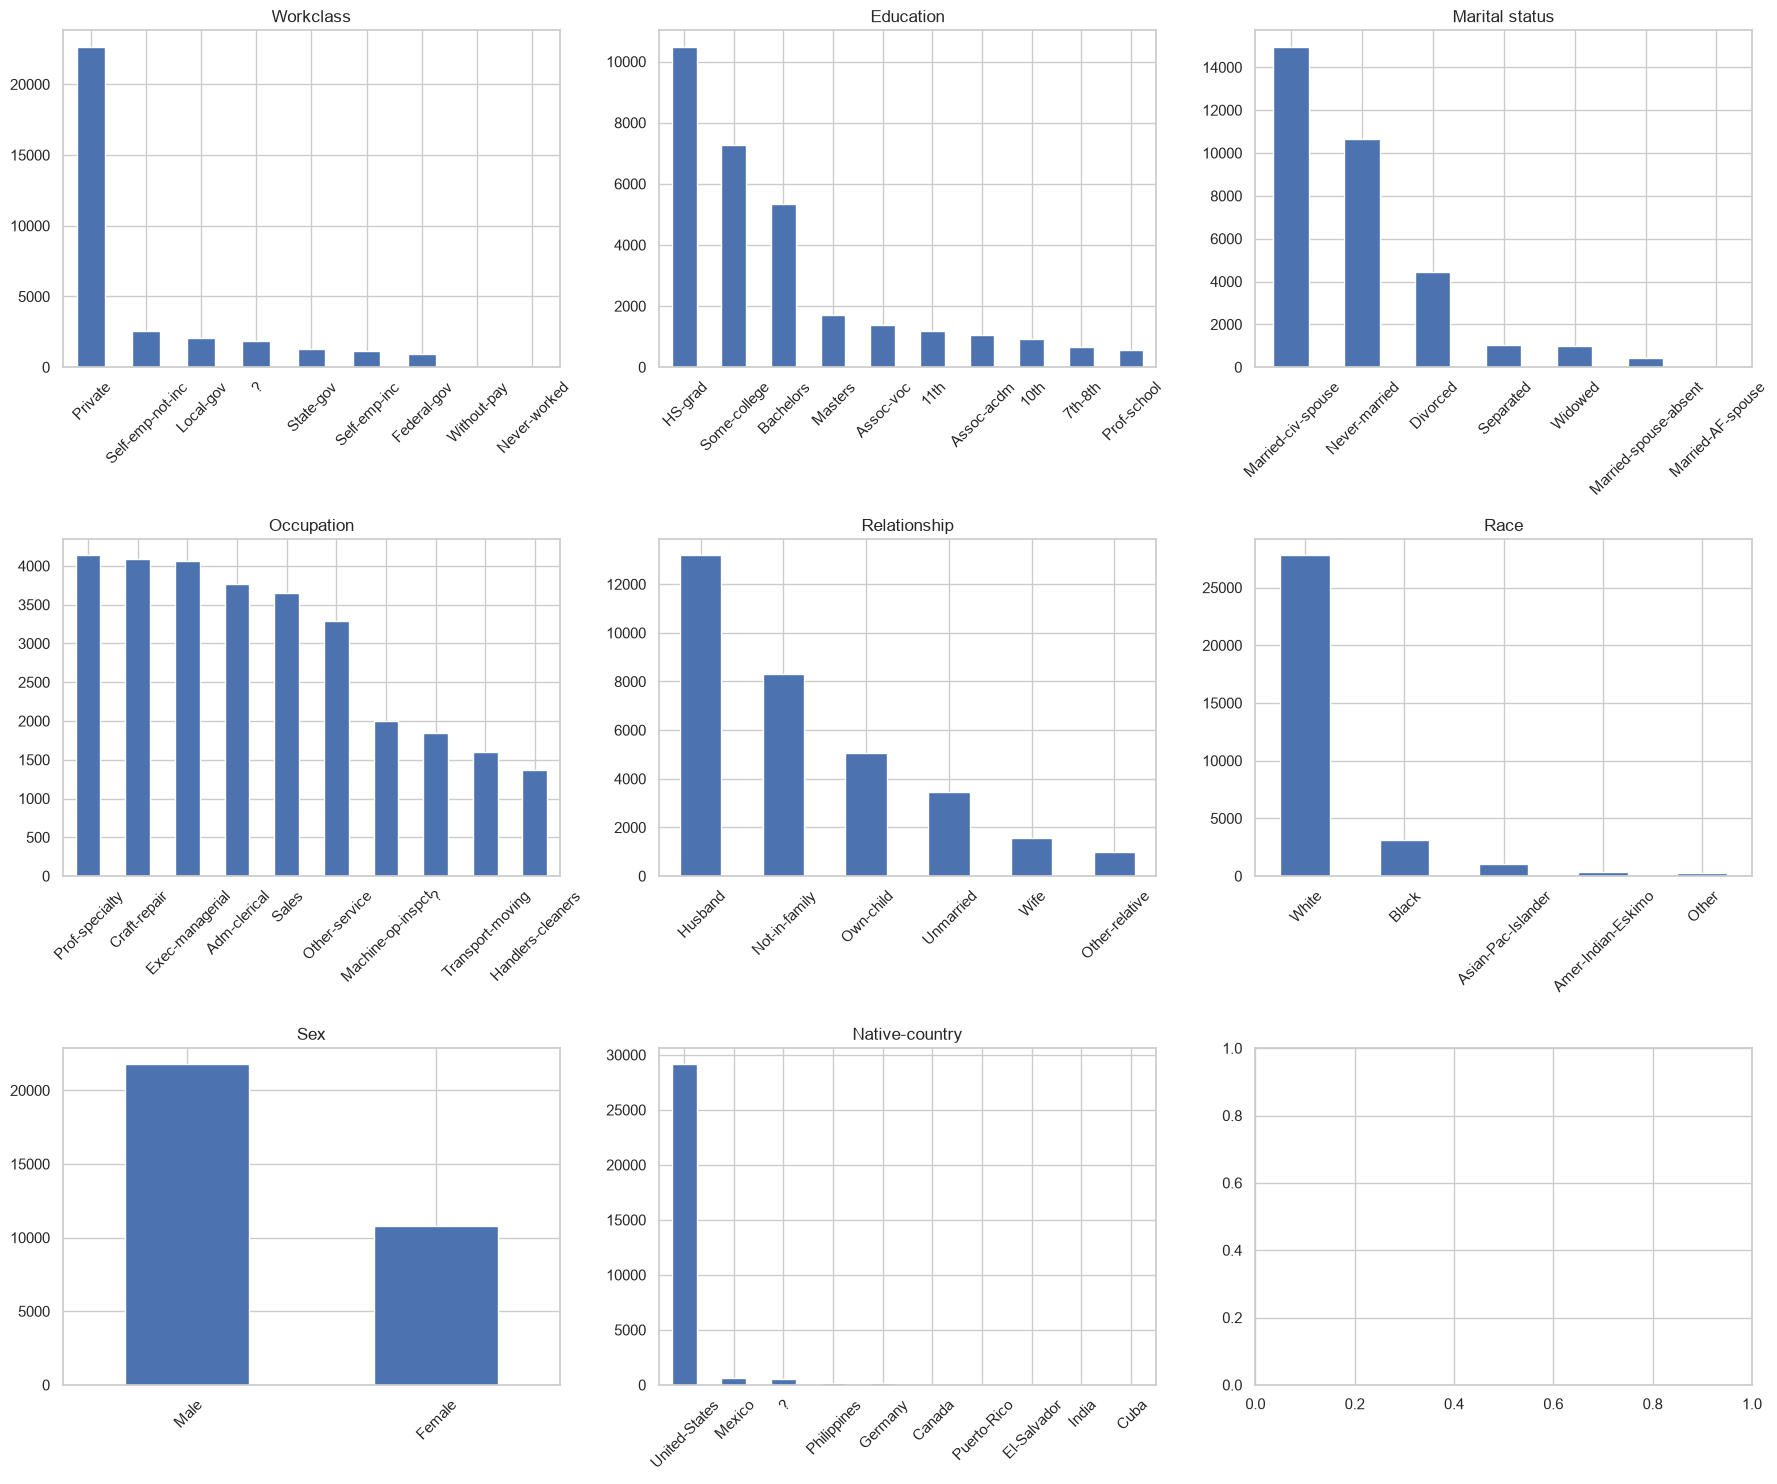

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))

for col, ax in zip(categorical_columns, axes.flatten()):
    train_df[col].value_counts().head(10).plot(
        kind="bar",
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [21]:
# Replace '?' with NaN again
train_df.replace(r'^\s*\?+\s*$', np.nan, regex=True, inplace=True)
test_df.replace(r'^\s*\?+\s*$', np.nan, regex=True, inplace=True)

# Verify
print("Training missing values:", train_df.isnull().sum().sum())
print("Testing missing values:", test_df.isnull().sum().sum())

print("\nMissing categorical values:")
print(train_df.select_dtypes(include="object").isnull().sum())

Training missing values: 4261
Testing missing values: 2203

Missing categorical values:
Workclass         1836
Education            0
Marital status       0
Occupation        1843
Relationship         0
Race                 0
Sex                  0
Native-country     582
Income               0
dtype: int64


C:\Users\sable\AppData\Local\Temp\ipykernel_13656\2580516864.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(train_df.select_dtypes(include="object").isnull().sum())


### Categorical Feature Analysis

1. Workclass: Private employment is the dominant category.
2. Education: HS-grad, Some-college and Bachelors are the most frequent.
3. Marital status: Married-civ-spouse is the largest category.
4. Occupation: Professional-specialty, Craft-repair and Executive-managerial are common.
5. Relationship: Husband is the most frequent category.
6. Race: White is the dominant category.
7. Sex: Male records are approximately twice the Female records.
8. Native-country: United-States accounts for the majority of observations.

### Key Observations

- Several categorical variables have highly imbalanced distributions.
- Missing categorical values need imputation.
- Native-country contains many low-frequency categories.
- Race and Sex are sensitive attributes and require fairness evaluation before any real-world deployment.

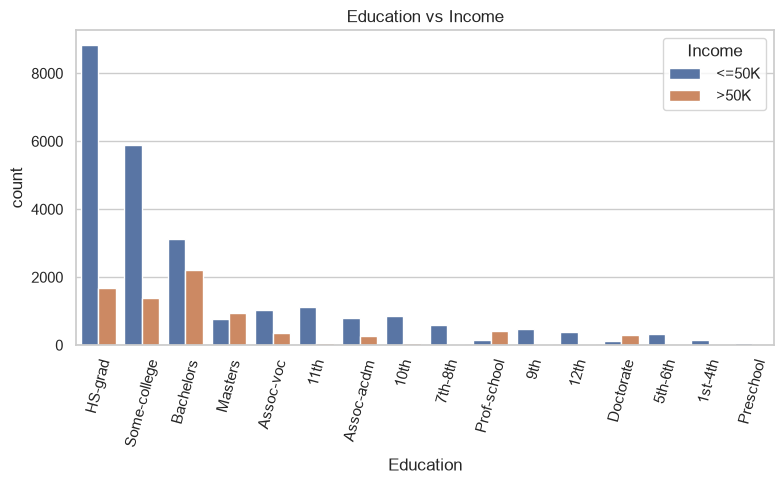

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="Education",
    hue="Income",
    order=train_df["Education"].value_counts().index
)

plt.title("Education vs Income")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

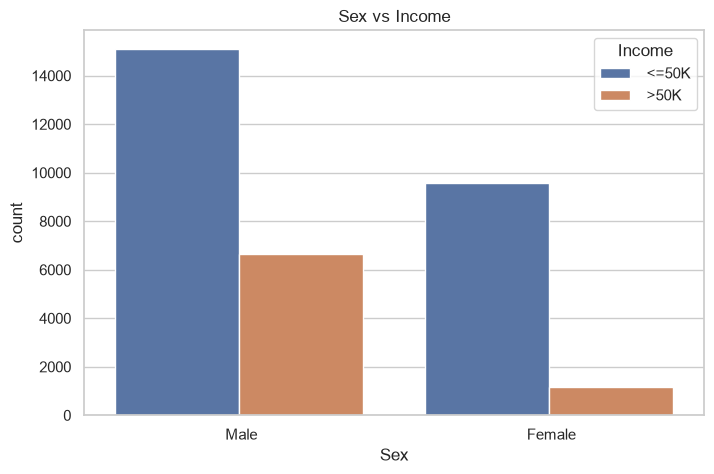

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="Sex",
    hue="Income"
)

plt.title("Sex vs Income")
plt.show()

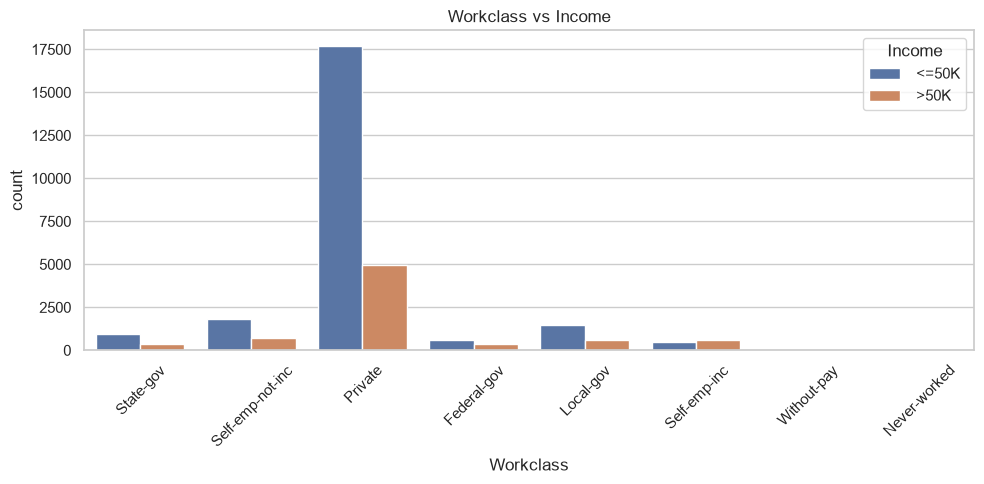

In [24]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    x="Workclass",
    hue="Income"
)

plt.title("Workclass vs Income")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
print(train_df["Workclass"].isnull().sum())
print(train_df["Occupation"].isnull().sum())
print(train_df["Native-country"].isnull().sum())

print("\nRemaining question marks:")
print((train_df == "?").sum().sum())

1836
1843
582

Remaining question marks:
0


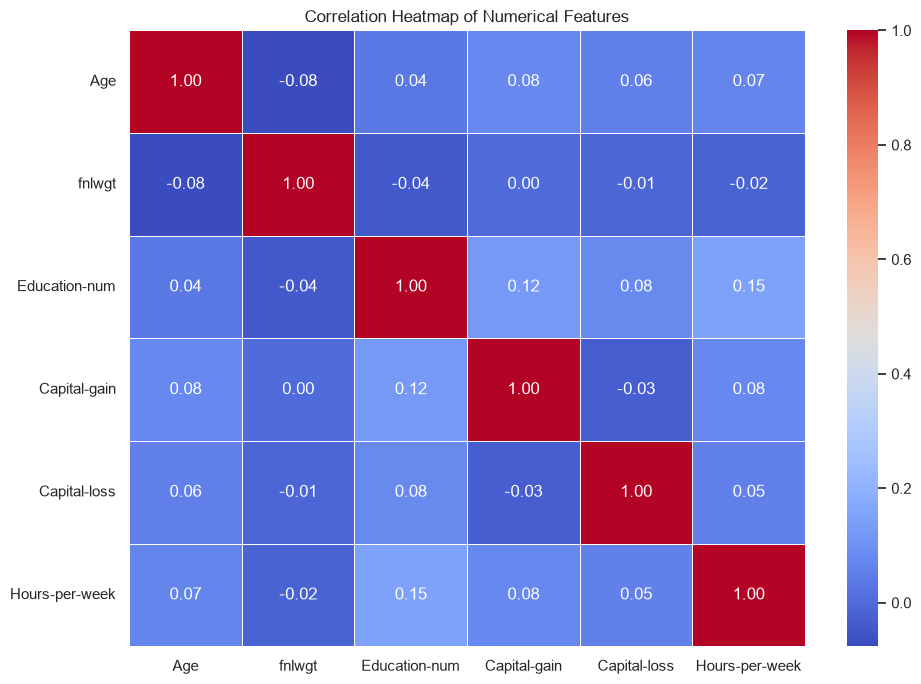

In [26]:
plt.figure(figsize=(10, 7))

correlation = train_df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [27]:
# Convert target into binary values for analysis
train_df["Income_binary"] = (
    train_df["Income"].str.strip() == ">50K"
).astype(int)

correlation_with_target = (
    train_df.select_dtypes(include=np.number)
    .corr()["Income_binary"]
    .sort_values(ascending=False)
)

print(correlation_with_target)

Income_binary     1.000000
Education-num     0.335273
Age               0.234031
Hours-per-week    0.229659
Capital-gain      0.223335
Capital-loss      0.150656
fnlwgt           -0.009529
Name: Income_binary, dtype: float64


In [28]:
# Separate target variable
X = train_df.drop(columns=["Income", "Income_binary"])

y = (
    train_df["Income"]
    .str.strip()
    .map({"<=50K": 0, ">50K": 1})
)

# Keep test features separate
X_test = test_df.drop(columns=["Income"])

y_test = (
    test_df["Income"]
    .str.strip()
    .map({"<=50K": 0, ">50K": 1})
)

print("Training features:", X.shape)
print("Training target:", y.shape)

print("\nTesting features:", X_test.shape)
print("Testing target:", y_test.shape)

print("\nTarget distribution:")
print(y.value_counts())

Training features: (32536, 14)
Training target: (32536,)

Testing features: (16276, 14)
Testing target: (16276,)

Target distribution:
Income
0    24697
1     7839
Name: count, dtype: int64


In [29]:
X = X.drop(columns=["fnlwgt"])
X_test = X_test.drop(columns=["fnlwgt"])

print("Features after removing fnlwgt:", X.shape[1])

Features after removing fnlwgt: 13


In [30]:
numerical_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['Age', 'Education-num', 'Capital-gain', 'Capital-loss', 'Hours-per-week']

Categorical features: ['Workclass', 'Education', 'Marital status', 'Occupation', 'Relationship', 'Race', 'Sex', 'Native-country']


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True) * 100)

X_train: (26028, 13)
X_val: (6508, 13)

Training target distribution:
Income
0    75.906716
1    24.093284
Name: proportion, dtype: float64

Validation target distribution:
Income
0    75.906577
1    24.093423
Name: proportion, dtype: float64


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [33]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)

Processed training shape: (26028, 103)
Processed validation shape: (6508, 103)


In [34]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# Create complete pipelines
model_pipelines = {}

for name, model in models.items():
    model_pipelines[name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

print("All model pipelines created successfully!")

All model pipelines created successfully!


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

results = []

for name, pipeline in model_pipelines.items():

    print(f"\nTraining {name}...")

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_val)

    # Probability of positive class (>50K)
    y_prob = pipeline.predict_proba(X_val)[:, 1]

    # Evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1 Score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

    print(f"{name} training completed!")

# Display comparison
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


Training Logistic Regression...
Logistic Regression training completed!

Training Random Forest...
Random Forest training completed!

Training Gradient Boosting...
Gradient Boosting training completed!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,0.8734,0.7995,0.6333,0.7068,0.9276
1,Random Forest,0.8694,0.8100,0.5982,0.6882,0.9219
2,Logistic Regression,0.8566,0.7429,0.6193,0.6755,0.9099


Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.95      0.92      4940
        >50K       0.80      0.63      0.71      1568

    accuracy                           0.87      6508
   macro avg       0.85      0.79      0.81      6508
weighted avg       0.87      0.87      0.87      6508



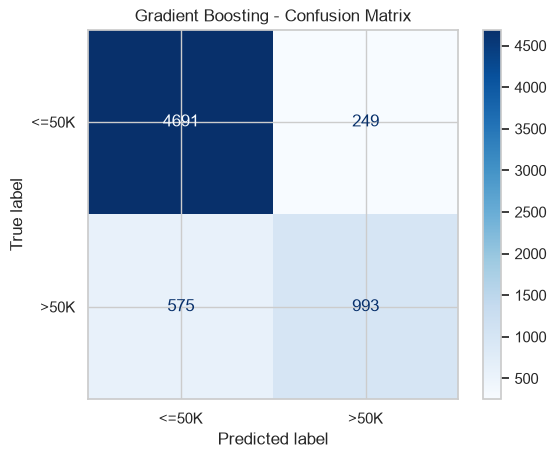

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Select the best model
best_model_name = "Gradient Boosting"
best_model = model_pipelines[best_model_name]

# Generate validation predictions
y_val_pred = best_model.predict(X_val)

# Classification report
print("Classification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["<=50K", ">50K"]
))

# Confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["<=50K", ">50K"]
)

disp.plot(cmap="Blues")
plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

In [37]:
# Get probability of positive class (>50K)
val_probabilities = best_model.predict_proba(X_val)[:, 1]

# Create customer prioritization DataFrame
priority_df = pd.DataFrame({
    "Actual_Income": y_val.values,
    "Predicted_Probability": val_probabilities
})

# Sort customers by predicted probability
priority_df = priority_df.sort_values(
    by="Predicted_Probability",
    ascending=False
).reset_index(drop=True)

# Select top 20% customers
top_20_count = int(np.ceil(len(priority_df) * 0.20))

top_20_customers = priority_df.head(top_20_count)

# Calculate prioritization metrics
actual_positive = (priority_df["Actual_Income"] == 1).sum()
captured_positive = (top_20_customers["Actual_Income"] == 1).sum()

precision_at_20 = captured_positive / top_20_count
recall_at_20 = captured_positive / actual_positive
lift_at_20 = precision_at_20 / (actual_positive / len(priority_df))

print("Customer Prioritization Results")
print("--------------------------------")
print("Total validation customers:", len(priority_df))
print("Top 20% customers selected:", top_20_count)
print("Actual positive customers in top 20%:", captured_positive)
print("Precision at 20%:", round(precision_at_20, 4))
print("Recall at 20%:", round(recall_at_20, 4))
print("Lift at 20%:", round(lift_at_20, 4))

# Display first 10 prioritized customers
display(top_20_customers.head(10))

Customer Prioritization Results
--------------------------------
Total validation customers: 6508
Top 20% customers selected: 1302
Actual positive customers in top 20%: 1023
Precision at 20%: 0.7857
Recall at 20%: 0.6524
Lift at 20%: 3.2611


,Actual_Income,Predicted_Probability
0,1,0.987186
1,1,0.987089
2,1,0.985818
3,1,0.984378
4,1,0.984013
5,1,0.983809
6,1,0.983347
7,1,0.981810
8,1,0.981613
9,1,0.980901


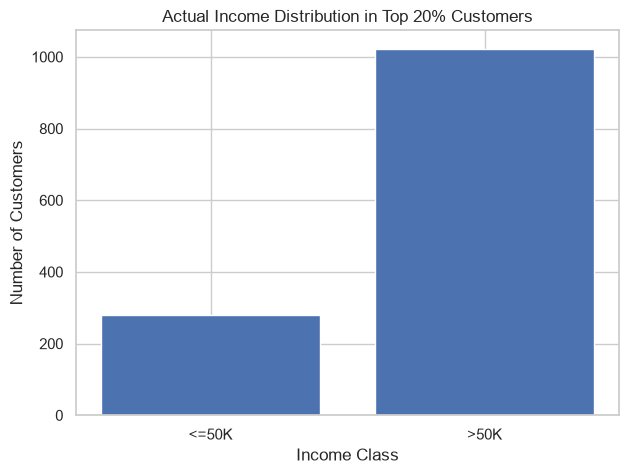

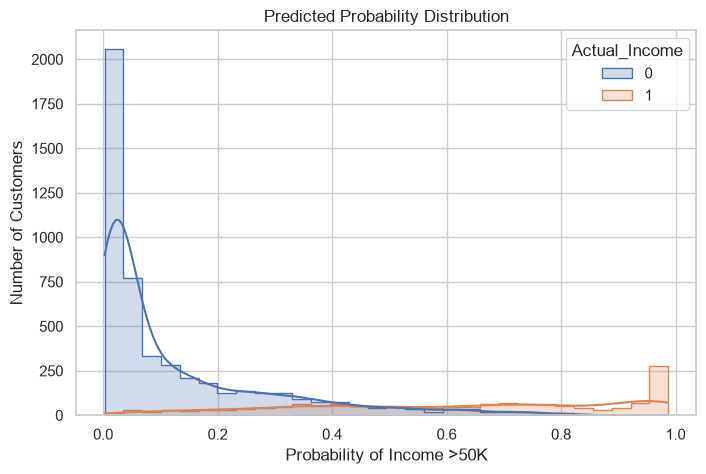

In [38]:
# 1. Actual positive vs negative customers in top 20%
priority_counts = top_20_customers["Actual_Income"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(
    ["<=50K", ">50K"],
    [
        priority_counts.get(0, 0),
        priority_counts.get(1, 0)
    ]
)
plt.title("Actual Income Distribution in Top 20% Customers")
plt.xlabel("Income Class")
plt.ylabel("Number of Customers")
plt.show()


# 2. Probability distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=priority_df,
    x="Predicted_Probability",
    hue="Actual_Income",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Predicted Probability Distribution")
plt.xlabel("Probability of Income >50K")
plt.ylabel("Number of Customers")
plt.show()

### Customer Prioritization Analysis

The Gradient Boosting classifier was used to rank customers based on their predicted probability of belonging to the `>50K` income category. The top 20% of validation customers (1,302 out of 6,508) were selected for prioritization.

Among these selected customers, 1,023 belonged to the positive class, resulting in a Precision@20% of 78.57%, Recall@20% of 65.24%, and Lift@20% of 3.26.

These results indicate that the model identifies a substantially higher concentration of positive-class customers within the prioritized segment compared with random selection. The probability distribution also demonstrates useful separation between the two income classes, although some overlap remains.

Therefore, Gradient Boosting is selected as the candidate model for customer ranking. The income category is used only as a proxy for prioritization and should not be interpreted as actual customer loyalty, shipping frequency, or profitability.

In [39]:
# Check test dataset columns
print("Test dataset shape:", test_df.shape)
print("Test dataset columns:", test_df.columns.tolist())

# Check target availability
print("Income column available:", "Income" in test_df.columns)

Test dataset shape: (16276, 15)
Test dataset columns: ['Age', 'Workclass', 'fnlwgt', 'Education', 'Education-num', 'Marital status', 'Occupation', 'Relationship', 'Race', 'Sex', 'Capital-gain', 'Capital-loss', 'Hours-per-week', 'Native-country', 'Income']
Income column available: True


In [40]:
# Prepare final training features and target
X_full = train_df.drop(
    columns=["Income", "Income_binary", "fnlwgt"],
    errors="ignore"
)

y_full = (
    train_df["Income"]
    .str.strip()
    .map({"<=50K": 0, ">50K": 1})
)

# Prepare test features
X_final_test = test_df.drop(
    columns=["Income", "fnlwgt"],
    errors="ignore"
)

# Keep actual test labels separately for offline evaluation
y_final_test = (
    test_df["Income"]
    .str.strip()
    .map({"<=50K": 0, ">50K": 1})
)

print("Final training features:", X_full.shape)
print("Final training target:", y_full.shape)
print("Final test features:", X_final_test.shape)
print("Final test target:", y_final_test.shape)

print("\nMissing training targets:", y_full.isna().sum())
print("Missing test targets:", y_final_test.isna().sum())

Final training features: (32536, 13)
Final training target: (32536,)
Final test features: (16276, 13)
Final test target: (16276,)

Missing training targets: 0
Missing test targets: 16276


In [41]:
# Train selected pipeline on all labeled training data
final_model = model_pipelines["Gradient Boosting"]

final_model.fit(X_full, y_full)

print("Final Gradient Boosting model trained successfully!")

Final Gradient Boosting model trained successfully!


In [42]:
# Predict probability of positive class (>50K)
test_probabilities = final_model.predict_proba(X_final_test)[:, 1]

# Create customer ranking
test_priority_df = pd.DataFrame({
    "Customer_ID": range(1, len(X_final_test) + 1),
    "Predicted_Probability": test_probabilities
})

# Rank customers by probability
test_priority_df = test_priority_df.sort_values(
    by="Predicted_Probability",
    ascending=False
).reset_index(drop=True)

# Assign priority ranks
test_priority_df["Priority_Rank"] = range(
    1, len(test_priority_df) + 1
)

# Select top 20%
top_20_test_count = int(np.ceil(len(test_priority_df) * 0.20))

top_20_test_customers = test_priority_df.head(top_20_test_count)

print("Final Test Customer Prioritization")
print("----------------------------------")
print("Total customers:", len(test_priority_df))
print("Top 20% selected:", len(top_20_test_customers))

display(top_20_test_customers.head(10))

Final Test Customer Prioritization
----------------------------------
Total customers: 16276
Top 20% selected: 3256


,Customer_ID,Predicted_Probability,Priority_Rank
0,5344,0.998405,1
1,4599,0.997779,2
2,6858,0.988035,3
3,979,0.987813,4
4,3269,0.987730,5
5,12485,0.987496,6
6,14087,0.986490,7
7,4782,0.986233,8
8,9815,0.985668,9
9,4211,0.984678,10


In [43]:
import os

os.makedirs("../outputs", exist_ok=True)

# Export all ranked customers
test_priority_df.to_csv(
    "../outputs/all_customer_rankings.csv",
    index=False
)

# Export top 20% customers
top_20_test_customers.to_csv(
    "../outputs/top_20_percent_customers.csv",
    index=False
)

print("Customer ranking files exported successfully!")

Customer ranking files exported successfully!


In [44]:
import joblib
import os

# Create models directory
os.makedirs("../models", exist_ok=True)

# Save complete trained pipeline
model_path = "../models/gradient_boosting_pipeline.pkl"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Model location:", model_path)

Model saved successfully!
Model location: ../models/gradient_boosting_pipeline.pkl


In [45]:
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")

# Test prediction using one test record
sample_prediction = loaded_model.predict_proba(
    X_final_test.iloc[:1]
)[:, 1]

print("Sample positive-class probability:", sample_prediction[0])

Model loaded successfully!
Sample positive-class probability: 0.012565986980532736


## 12. Fairness Analysis

Race and Sex are sensitive attributes. To evaluate their influence
on model predictions, two models are compared:

1. Baseline model: Uses all available features.
2. Reduced-feature model: Excludes Race and Sex.

Both models use the same stratified training and validation split.
Their predictive performance and subgroup metrics are compared.

In [46]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Remove sensitive attributes from model features
sensitive_features = ["Race", "Sex"]

features_without_sensitive = [
    col for col in X_train.columns
    if col not in sensitive_features
]

# Separate numerical and categorical features
numerical_features_fair = [
    col for col in numerical_features
    if col in features_without_sensitive
]

categorical_features_fair = [
    col for col in categorical_features
    if col in features_without_sensitive
]

# Numerical preprocessing
numerical_transformer_fair = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_fair = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor_fair = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer_fair, numerical_features_fair),
        ("cat", categorical_transformer_fair, categorical_features_fair)
    ]
)

# Create reduced-feature model
fairness_model = Pipeline(steps=[
    ("preprocessor", preprocessor_fair),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train using the same training split
fairness_model.fit(
    X_train[features_without_sensitive],
    y_train
)

print("Fairness comparison model trained successfully.")
print("Features used:", len(features_without_sensitive))
print(features_without_sensitive)


Fairness comparison model trained successfully.
Features used: 11
['Age', 'Workclass', 'Education', 'Education-num', 'Marital status', 'Occupation', 'Relationship', 'Capital-gain', 'Capital-loss', 'Hours-per-week', 'Native-country']


In [47]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Predictions from original model
baseline_model = model_pipelines["Gradient Boosting"]

baseline_predictions = baseline_model.predict(X_val)
baseline_probabilities = baseline_model.predict_proba(X_val)[:, 1]

# Predictions from model without Race and Sex
fair_predictions = fairness_model.predict(
    X_val[features_without_sensitive]
)

fair_probabilities = fairness_model.predict_proba(
    X_val[features_without_sensitive]
)[:, 1]

# Calculate performance metrics
comparison = pd.DataFrame([
    {
        "Model": "Baseline (All Features)",
        "Accuracy": accuracy_score(y_val, baseline_predictions),
        "Precision": precision_score(y_val, baseline_predictions),
        "Recall": recall_score(y_val, baseline_predictions),
        "F1 Score": f1_score(y_val, baseline_predictions),
        "ROC-AUC": roc_auc_score(y_val, baseline_probabilities)
    },
    {
        "Model": "Without Race and Sex",
        "Accuracy": accuracy_score(y_val, fair_predictions),
        "Precision": precision_score(y_val, fair_predictions),
        "Recall": recall_score(y_val, fair_predictions),
        "F1 Score": f1_score(y_val, fair_predictions),
        "ROC-AUC": roc_auc_score(y_val, fair_probabilities)
    }
])

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline (All Features),0.8748,0.8029,0.6365,0.7101,0.9313
1,Without Race and Sex,0.8729,0.7966,0.6346,0.7064,0.9266


In [48]:

def calculate_group_metrics(
    y_true,
    y_pred,
    group_values,
    model_name,
    feature_name
):
    data = pd.DataFrame({
        "actual": y_true.to_numpy(),
        "predicted": y_pred,
        "group": group_values.to_numpy()
    })

    results = []

    for group, group_data in data.groupby("group", dropna=False):

        actual = group_data["actual"]
        predicted = group_data["predicted"]

        tp = ((actual == 1) & (predicted == 1)).sum()
        fp = ((actual == 0) & (predicted == 1)).sum()
        fn = ((actual == 1) & (predicted == 0)).sum()
        tn = ((actual == 0) & (predicted == 0)).sum()

        results.append({
            "Model": model_name,
            "Sensitive Feature": feature_name,
            "Group": str(group),
            "Count": len(group_data),

            # Percentage predicted as positive
            "Selection Rate": predicted.mean(),

            # Actual positive cases correctly identified
            "True Positive Rate": (
                tp / (tp + fn) if (tp + fn) else 0
            ),

            # Actual negative cases incorrectly identified
            "False Positive Rate": (
                fp / (fp + tn) if (fp + tn) else 0
            ),

            "Precision": (
                tp / (tp + fp) if (tp + fp) else 0
            )
        })

    return results


# Combine baseline and reduced-model predictions
group_results = []

for model_name, predictions in [
    ("Baseline", baseline_predictions),
    ("Without Race and Sex", fair_predictions)
]:

    for feature in sensitive_features:

        group_results.extend(
            calculate_group_metrics(
                y_val,
                predictions,
                X_val[feature],
                model_name,
                feature
            )
        )

fairness_results = pd.DataFrame(group_results)

display(
    fairness_results.round(4)
)


,Model,Sensitive Feature,Group,Count,Selection Rate,True Positive Rate,False Positive Rate,Precision
0,Baseline,Race,Amer-Indian-Eskimo,62,0.0484,0.3333,0.0000,1.0000
1,Baseline,Race,Asian-Pac-Islander,207,0.2560,0.6909,0.0987,0.7170
2,Baseline,Race,Black,651,0.0814,0.5402,0.0106,0.8868
3,Baseline,Race,Other,64,0.0625,1.0000,0.0000,1.0000
4,Baseline,Race,White,5524,0.2046,0.6412,0.0545,0.8018
5,Baseline,Sex,Female,2144,0.0779,0.5630,0.0127,0.8563
6,Baseline,Sex,Male,4364,0.2466,0.6507,0.0725,0.7946
7,Without Race and Sex,Race,Amer-Indian-Eskimo,62,0.0645,0.4444,0.0000,1.0000
8,Without Race and Sex,Race,Asian-Pac-Islander,207,0.2705,0.6727,0.1250,0.6607
9,Without Race and Sex,Race,Black,651,0.0891,0.5632,0.0160,0.8448


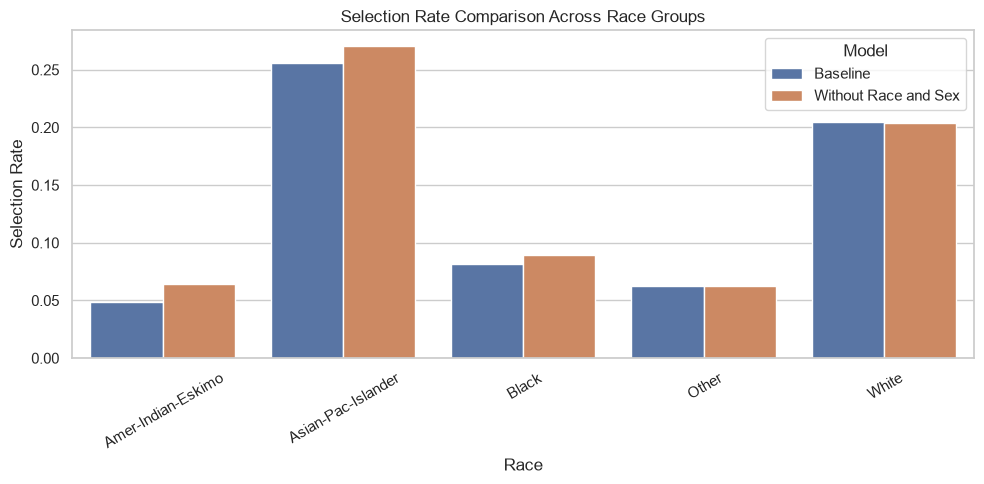

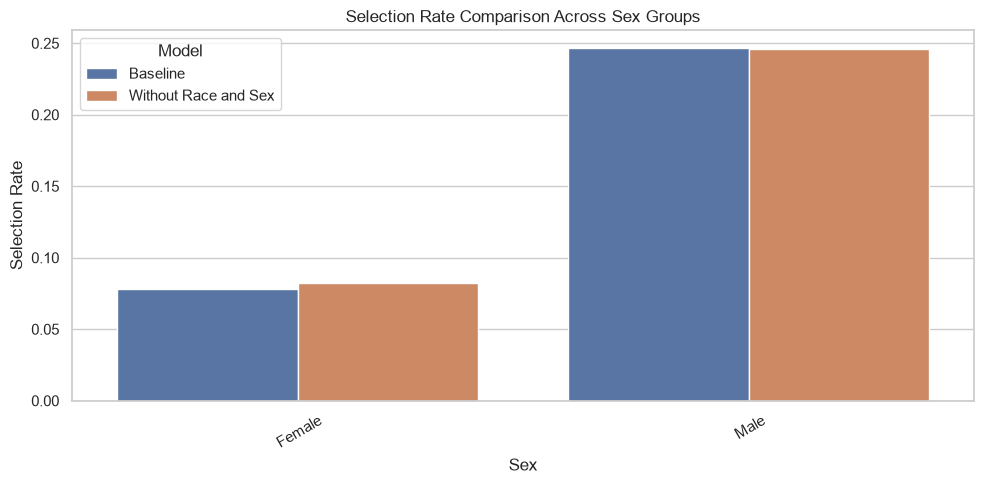

In [49]:

import matplotlib.pyplot as plt
import seaborn as sns

for feature in sensitive_features:

    subset = fairness_results[
        fairness_results["Sensitive Feature"] == feature
    ]

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=subset,
        x="Group",
        y="Selection Rate",
        hue="Model"
    )

    plt.title(f"Selection Rate Comparison Across {feature} Groups")
    plt.ylabel("Selection Rate")
    plt.xlabel(feature)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


In [50]:

# Exclude sensitive attributes and Relationship
excluded_features = ["Race", "Sex", "Relationship"]

features_proxy_removed = [
    col for col in X_train.columns
    if col not in excluded_features
]

num_features_proxy = [
    col for col in numerical_features
    if col in features_proxy_removed
]

cat_features_proxy = [
    col for col in categorical_features
    if col in features_proxy_removed
]

# Preprocessing
preprocessor_proxy = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_features_proxy),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_features_proxy)
    ]
)

# Model
proxy_removed_model = Pipeline([
    ("preprocessor", preprocessor_proxy),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train
proxy_removed_model.fit(
    X_train[features_proxy_removed],
    y_train
)

print("Third fairness experiment trained successfully.")
print("Features used:", len(features_proxy_removed))
print(features_proxy_removed)


Third fairness experiment trained successfully.
Features used: 10
['Age', 'Workclass', 'Education', 'Education-num', 'Marital status', 'Occupation', 'Capital-gain', 'Capital-loss', 'Hours-per-week', 'Native-country']


In [51]:

proxy_predictions = proxy_removed_model.predict(
    X_val[features_proxy_removed]
)

proxy_probabilities = proxy_removed_model.predict_proba(
    X_val[features_proxy_removed]
)[:, 1]

third_model_metrics = {
    "Model": "Without Race, Sex and Relationship",
    "Accuracy": accuracy_score(y_val, proxy_predictions),
    "Precision": precision_score(y_val, proxy_predictions),
    "Recall": recall_score(y_val, proxy_predictions),
    "F1 Score": f1_score(y_val, proxy_predictions),
    "ROC-AUC": roc_auc_score(y_val, proxy_probabilities)
}

comparison = pd.concat([
    comparison,
    pd.DataFrame([third_model_metrics])
], ignore_index=True)

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline (All Features),0.8748,0.8029,0.6365,0.7101,0.9313
1,Without Race and Sex,0.8729,0.7966,0.6346,0.7064,0.9266
2,"Without Race, Sex and Relationship",0.8714,0.7964,0.6263,0.7012,0.9253


In [52]:

proxy_group_results = calculate_group_metrics(
    y_val,
    proxy_predictions,
    X_val["Sex"],
    "Without Race, Sex and Relationship",
    "Sex"
)

proxy_group_df = pd.DataFrame(proxy_group_results)

display(proxy_group_df.round(4))


,Model,Sensitive Feature,Group,Count,Selection Rate,True Positive Rate,False Positive Rate,Precision
0,"Without Race, Sex and Relationship",Sex,Female,2144,0.0695,0.4961,0.0122,0.8456
1,"Without Race, Sex and Relationship",Sex,Male,4364,0.2484,0.6514,0.0748,0.7897
